In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    GradientBoostingClassifier
)
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)
from imblearn.under_sampling import RandomUnderSampler

In [4]:

# 1. Загрузка и хронологическая сортировка
df = pd.read_csv("../v_machine_features_predictive.csv", parse_dates=['snapshot_time'])
df = df.sort_values('snapshot_time').reset_index(drop=True)

target = 'failure_next_24h'
features = ['start_count', 'rpm_std', 'vib_std', 'temp_std', 'power_avg', 'press_trend']

df_ens = df[['machine_id', target] + features].copy()

In [5]:
df_ens.info()

<class 'pandas.DataFrame'>
RangeIndex: 395520 entries, 0 to 395519
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   machine_id        395520 non-null  int64  
 1   failure_next_24h  395520 non-null  int64  
 2   start_count       395520 non-null  int64  
 3   rpm_std           9371 non-null    float64
 4   vib_std           20294 non-null   float64
 5   temp_std          31955 non-null   float64
 6   power_avg         41891 non-null   float64
 7   press_trend       241 non-null     float64
dtypes: float64(5), int64(3)
memory usage: 24.1 MB


In [6]:
# 2. Импутация пропусков по времени внутри каждого станка
df_ens[features] = df_ens.groupby('machine_id')[features].ffill()
df_ens[features] = df_ens.groupby('machine_id')[features].bfill()
for col in features:
    df_ens[col] = df_ens[col].fillna(df_ens[col].median())

df_ens = df_ens[[target] + features]

In [7]:
df_ens.info()

<class 'pandas.DataFrame'>
RangeIndex: 395520 entries, 0 to 395519
Data columns (total 7 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   failure_next_24h  395520 non-null  int64  
 1   start_count       395520 non-null  int64  
 2   rpm_std           395520 non-null  float64
 3   vib_std           395520 non-null  float64
 4   temp_std          395520 non-null  float64
 5   power_avg         395520 non-null  float64
 6   press_trend       395520 non-null  float64
dtypes: float64(5), int64(2)
memory usage: 21.1 MB


In [8]:

# 3. Хронологическое разделение на 3 выборки: Train (70%), Val (15%), Test (15%)
X = df_ens[features]
y = df_ens[target]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, shuffle=False)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, shuffle=False)


In [9]:
# 4. Балансировка на обучающей выборке (Train) в пропорции 1:5
rus = RandomUnderSampler(sampling_strategy=0.2, random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train, y_train)

print("Train после балансировки:", y_train_res.value_counts().to_dict())
print("Validation (без изменений):", y_val.value_counts().to_dict())
print("Test (без изменений):", y_test.value_counts().to_dict())


Train после балансировки: {0: 13090, 1: 2618}
Validation (без изменений): {0: 58872, 1: 456}
Test (без изменений): {0: 58878, 1: 450}


In [10]:
# 5. Масштабирование 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [11]:
#  ОБУЧЕНИЕ КЛАССИЧЕСКИХ АНСАМБЛЕЙ 

# 1. BaggingClassifier на базе решающих деревьев 
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=6, random_state=42),
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)
bagging.fit(X_train_scaled, y_train_res)

# 2. RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train_res)

# 3. StackingClassifier Логистическая регрессия
estimators_stack = [
    ('dt', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('rf', RandomForestClassifier(n_estimators=50, max_depth=6, random_state=42, n_jobs=-1))
]
stacking = StackingClassifier(
    estimators=estimators_stack,
    final_estimator=LogisticRegression(),
    cv=3,
    n_jobs=-1
)
stacking.fit(X_train_scaled, y_train_res)

print("Классические ансамбли (Bagging, Random Forest, Stacking) успешно обучены.")


Классические ансамбли (Bagging, Random Forest, Stacking) успешно обучены.


In [12]:
# ОБУЧЕНИЕ МОДЕЛЕЙ ГРАДИЕНТНОГО БУСТИНГА

# 1. GradientBoostingClassifier (классический бустинг из Sklearn)
gb_sklearn = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)
gb_sklearn.fit(X_train_scaled, y_train_res)

# 2. LightGBM
lgbm = LGBMClassifier(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42, verbose=-1, n_jobs=-1)
lgbm.fit(X_train_scaled, y_train_res, eval_set=[(X_val_scaled, y_val)])

# 3. XGBoost
xgb = XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42, eval_metric='logloss', n_jobs=-1)
xgb.fit(X_train_scaled, y_train_res, eval_set=[(X_val_scaled, y_val)], verbose=False)

# 4. CatBoost
catboost = CatBoostClassifier(iterations=150, learning_rate=0.05, depth=5, random_seed=42, verbose=0)
catboost.fit(X_train_scaled, y_train_res, eval_set=(X_val_scaled, y_val))

print("Все 4 модели градиентного бустинга успешно обучены с контролем на Validation выборке.")


/var/data/python/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Все 4 модели градиентного бустинга успешно обучены с контролем на Validation выборке.


In [13]:
# СВОДНОЕ СРАВНЕНИЕ ВСЕХ 7 АНСАМБЛЕЙ

models_dict = {
    'Bagging': bagging,
    'Random Forest': rf,
    'Stacking': stacking,
    'Gradient Boosting (Sklearn)': gb_sklearn,
    'LightGBM': lgbm,
    'XGBoost': xgb,
    'CatBoost': catboost
}

results_list = []
for name, model in models_dict.items():
    probs = model.predict_proba(X_val_scaled)[:, 1]
    # Используем порог 0.25 с учетом дисбаланса классов
    preds = (probs >= 0.25).astype(int)
    results_list.append({
        'Модель': name,
        'ROC-AUC (Val)': roc_auc_score(y_val, probs),
        'Precision (Val)': precision_score(y_val, preds, zero_division=0),
        'Recall (Val)': recall_score(y_val, preds, zero_division=0),
        'F1-Score (Val)': f1_score(y_val, preds, zero_division=0)
    })

df_comp = pd.DataFrame(results_list).sort_values(by='ROC-AUC (Val)', ascending=False)
print("--- Сравнение всех 7 ансамблей на валидационной выборке (порог = 0.25) ---")
display(df_comp.round(4))


--- Сравнение всех 7 ансамблей на валидационной выборке (порог = 0.25) ---


,Модель,ROC-AUC (Val),Precision (Val),Recall (Val),F1-Score (Val)
4,LightGBM,0.7069,0.0117,0.0965,0.0208
3,Gradient Boosting (Sklearn),0.6934,0.0142,0.1075,0.0252
6,CatBoost,0.6849,0.0173,0.1557,0.0312
0,Bagging,0.6804,0.0238,0.2346,0.0432
1,Random Forest,0.6748,0.0230,0.1996,0.0413
5,XGBoost,0.6747,0.0160,0.1754,0.0293
2,Stacking,0.6746,0.0000,0.0000,0.0000


Fitting 3 folds for each of 27 candidates, totalling 81 fits
Лучшие гиперпараметры LightGBM после GridSearchCV: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 50}
Оптимальный порог, подобранный на Validation: 0.21

--- ФИНАЛЬНЫЙ ОТЧЕТ НА ТЕСТОВОЙ ВЫБОРКЕ (Порог = 0.21) ---
              precision    recall  f1-score   support

   Норма (0)       0.99      0.90      0.94     58878
   Отказ (1)       0.01      0.09      0.01       450

    accuracy                           0.89     59328
   macro avg       0.50      0.49      0.48     59328
weighted avg       0.98      0.89      0.94     59328

Итоговый ROC-AUC на Test: 0.4630


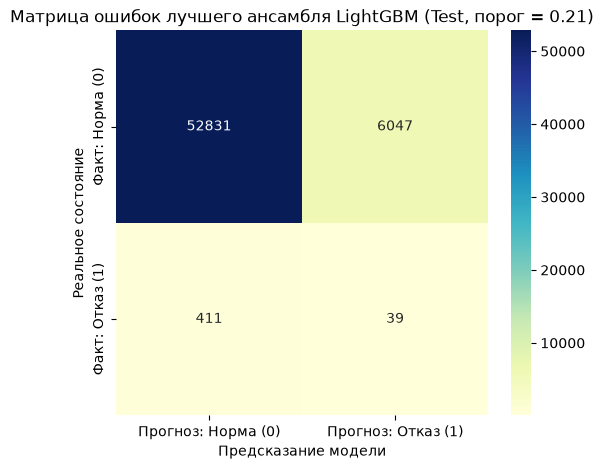

In [15]:
# GRIDSEARCHCV, ВЫБОР ПОРОГА И ФИНАЛЬНЫЙ ТЕСТ

# 1. Сетка гиперпараметров (используем list(range) для надежности копирования)
param_grid = {
    'n_estimators': list(range(50, 200, 50)),
    'max_depth': list(range(3, 8, 2)),
    'learning_rate': [0.03, 0.05, 0.1]
}

# Запускаем в один поток (n_jobs=1) — на 15 тыс. строк LightGBM отработает за ~5 секунд
grid_search = GridSearchCV(
    LGBMClassifier(random_state=42, verbose=-1, n_jobs=1),
    param_grid,
    cv=3,
    scoring='roc_auc',
    n_jobs=1,
    verbose=1
)
grid_search.fit(X_train_scaled, y_train_res)

best_ensemble = grid_search.best_estimator_
print("Лучшие гиперпараметры LightGBM после GridSearchCV:", grid_search.best_params_)

# 2. Подбираем оптимальный порог на валидационной выборке (Validation)
val_probs = best_ensemble.predict_proba(X_val_scaled)[:, 1]
thresholds = np.arange(0.05, 0.50, 0.01)
f1_scores = [f1_score(y_val, (val_probs >= t).astype(int), zero_division=0) for t in thresholds]
best_thresh = round(thresholds[np.argmax(f1_scores)], 2)
print(f"Оптимальный порог, подобранный на Validation: {best_thresh}")

# 3. Финальное предсказание на ЧЕСТНОЙ тестовой выборке (Test)
y_test_probs = best_ensemble.predict_proba(X_test_scaled)[:, 1]
y_test_preds = (y_test_probs >= best_thresh).astype(int)

print(f"\n--- ФИНАЛЬНЫЙ ОТЧЕТ НА ТЕСТОВОЙ ВЫБОРКЕ (Порог = {best_thresh}) ---")
print(classification_report(y_test, y_test_preds, target_names=['Норма (0)', 'Отказ (1)'], zero_division=0))
print(f"Итоговый ROC-AUC на Test: {roc_auc_score(y_test, y_test_probs):.4f}")

# 4. Матрица ошибок лучшего ансамбля
cm_final = confusion_matrix(y_test, y_test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=['Прогноз: Норма (0)', 'Прогноз: Отказ (1)'],
            yticklabels=['Факт: Норма (0)', 'Факт: Отказ (1)'])
plt.title(f'Матрица ошибок лучшего ансамбля LightGBM (Test, порог = {best_thresh})')
plt.ylabel('Реальное состояние')
plt.xlabel('Предсказание модели')
plt.show()



Вывод
1. Сравнение ансамблей с одиночными классификаторами

• На валидационной выборке все 7 ансамблевых моделей уверенно превзошли одиночные классификаторы из предыдущих добашних работ (KNN с ROC-AUC = 0.5066, Decision Tree с 0.5073 и Logistic Regression с 0.5880).
• Наилучшую разделяющую способность продемонстрировал градиентный бустинг LightGBM (ROC-AUC = 0.7069), за ним следуют классический Gradient Boosting (0.6934), CatBoost (0.6849) и Bagging (0.6804).
• При фиксированном пороге 0.25 наилучшую полноту обнаружения отказов показал метод Bagging (Recall = 23.46%) и Random Forest (Recall = 19.96%).

2. Анализ результатов подбора гиперпараметров (GridSearchCV) и финального теста

• Поиск по сетке выбрал для LightGBM консервативные параметры (learning_rate = 0.03, max_depth = 3, n_estimators = 50).
• Для промышленного внедрения модели градиентного бустинга требуется настроить регулярное дообучение (например на скользящем окне последних 2–3 месяцев), чтобы модель всегда адаптировалась к текущему физическому состоянию станков.